In [1]:
!git clone --quiet --depth 1 --branch rev1 https://github.com/huboqiang/omnialigner.git omnialigner-rev1
!wget -q -c -O rev1-fig4-brca-data.tar.gz https://github.com/huboqiang/omnialigner/releases/download/rev1/rev1-fig4-brca-data.tar.gz
!pip install -q numpy==1.26.0 scipy==1.15.3 pandas==2.1.1 matplotlib==3.9.1 seaborn==0.13.2

Reason for being yanked: <none given>


# Fig. 4A: original BRCA prediction benchmark

Recompute the original two-direction OmniPred/SpatialEx comparison from the measured and frozen predicted expression arrays. Each point in the boxplot is **one gene's Pearson correlation across cells**, not a within-cell profile correlation. The two sections belong to the same breast-cancer tissue block.

This notebook reproduces the original figure cohort and model outputs; it does not substitute the later revision benchmark or retrain the predictors. Use a fresh Python 3.10/3.11 kernel, `git`, `wget`, approximately 6 GB free RAM and 3 GB free disk. All numerical inputs are public downloads; no server directory or credentials are needed.

In [1]:
from pathlib import Path
import hashlib, json, sys, tarfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from IPython.display import display

assert (3, 10) <= sys.version_info[:2] < (3, 12), "Use Python 3.10 or 3.11."
def sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for chunk in iter(lambda: stream.read(8 * 1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

archive = Path("rev1-fig4-brca-data.tar.gz")
assert sha256(archive) == "76e2c5a31e9c85a2e2ed6365ada32365396efbfe2e3770e05e165c9de2e0d89a", "Unexpected data archive"
data_root = Path("fig4_brca_data").resolve()
data_root.mkdir(exist_ok=True)
with tarfile.open(archive, "r:gz") as bundle:
    for member in bundle.getmembers():
        assert (data_root / member.name).resolve().is_relative_to(data_root)
        assert not member.issym() and not member.islnk()
    bundle.extractall(data_root)
DATA = data_root / "fig4_brca"
OUTPUT = Path("fig4_brca_results")
OUTPUT.mkdir(exist_ok=True)
manifest = json.loads((DATA / "manifest.json").read_text())
for name, entry in manifest.items():
    assert sha256(DATA / name) == entry["sha256"], name
print("All downloaded inputs passed SHA-256 checks.")

All downloaded inputs passed SHA-256 checks.


## 1. Confirm the original cell and gene identities

S1 contains 164,000 cells; the S2 evaluation subset contains 111,555 cells. The original S2 OmniPred prediction contains 118,370 rows. The export restores the original preprocessed Xenium cell order and selects the evaluation cells by their IDs, exactly as source cell 28 does. The supplied `original_row_indices` makes this selection inspectable; it is not a prefix truncation.

Measured expression uses the original preprocessing: retain cells with at least 10 transcripts, normalize each cell to the median retained library size, and apply `log1p`, **before** selecting the evaluation subset. The original source assigns prediction identities positionally; the archived row mapping documents that historical assumption.

In [2]:
DIRECTIONS = ["2_to_1", "1_to_2"]
METHODS = ["SpatialEx", "OmniPred"]
cohorts = {}
for direction in DIRECTIONS:
    with np.load(DATA / f"{direction}.npz", allow_pickle=False) as stored:
        cohort = {name: stored[name] for name in stored.files}
    ids, genes = cohort["cell_ids"], cohort["gene_names"]
    assert len(np.unique(ids)) == len(ids)
    assert len(np.unique(genes)) == 313
    assert np.array_equal(cohort["original_cell_ids"][cohort["original_row_indices"]], ids)
    for name in ["truth", *METHODS]:
        assert cohort[name].shape == (len(ids), len(genes))
        assert np.isfinite(cohort[name]).all()
    cohorts[direction] = cohort
    print(direction, ":", len(ids), "evaluation cells,", len(genes), "genes; original rows:",
          len(cohort["original_cell_ids"]))
assert np.array_equal(cohorts["2_to_1"]["gene_names"], cohorts["1_to_2"]["gene_names"])
provenance = json.loads((DATA / "provenance.json").read_text())
display(pd.DataFrame([{ "direction": d, "cells": p["n_cells"], "genes": p["n_genes"],
                       "truth_vs_saved_max_abs_difference": p["saved_truth_max_abs_difference"]}
                      for d, p in provenance.items()]))

2_to_1 : 164000 evaluation cells, 313 genes; original rows: 164000


1_to_2 : 111555 evaluation cells, 313 genes; original rows: 118370


,direction,cells,genes,truth_vs_saved_max_abs_difference
0,2_to_1,164000,313,0.0
1,1_to_2,111555,313,0.0


## 2. Calculate Pearson correlation explicitly

For each gene, subtract the mean across cells from its measured and predicted expression. Pearson correlation is the sum of the centered products divided by the product of their Euclidean norms:

$$r_g=\frac{\sum_i (y_{ig}-\bar y_g)(\hat y_{ig}-\bar{\hat y}_g)}{\sqrt{\sum_i(y_{ig}-\bar y_g)^2}\sqrt{\sum_i(\hat y_{ig}-\bar{\hat y}_g)^2}}.$$

The code below implements that formula directly. Constant genes remain `NaN`; they are not replaced by zero. The archived code multiplies OmniPred predictions by 5. We preserve this float32 operation before scoring; a positive constant does not change Pearson correlation mathematically.

In [3]:
def gene_pcc(measured, predicted):
    """One Pearson correlation per gene; rows=cells, columns=genes."""
    # Retain float32 and the historical operation order to reproduce the source scores.
    measured = np.asarray(measured, dtype=np.float32)
    predicted = np.asarray(predicted, dtype=np.float32)
    measured_centered = measured - measured.mean(axis=0, keepdims=True)
    predicted_centered = predicted - predicted.mean(axis=0, keepdims=True)
    measured_scale = np.max(np.abs(measured_centered), axis=0, keepdims=True)
    predicted_scale = np.max(np.abs(predicted_centered), axis=0, keepdims=True)
    with np.errstate(invalid="ignore", divide="ignore"):
        measured_norm = measured_scale * np.linalg.norm(
            measured_centered / measured_scale, axis=0, keepdims=True)
        predicted_norm = predicted_scale * np.linalg.norm(
            predicted_centered / predicted_scale, axis=0, keepdims=True)
        correlations = np.sum(measured_centered / measured_norm *
                              predicted_centered / predicted_norm, axis=0)
    correlations = np.clip(correlations, -1, 1)
    constant = np.all(measured == measured[:1], axis=0) | np.all(predicted == predicted[:1], axis=0)
    correlations[constant] = np.nan
    return correlations

records, scipy_records = [], []
for direction, cohort in cohorts.items():
    measured = cohort["truth"]
    for method in METHODS:
        predicted = cohort[method]
        if method == "OmniPred":
            predicted = predicted * np.float32(5.0)
        correlations = gene_pcc(measured, predicted)
        # Independent check against the original notebook's SciPy call.
        original_correlations = pearsonr(measured, predicted, axis=0).statistic
        for gene, value, original in zip(cohort["gene_names"], correlations, original_correlations):
            records.append(dict(direction=direction, method=method, gene=gene, PCC=value))
            scipy_records.append(dict(direction=direction, method=method, gene=gene, PCC=original))
scores = pd.DataFrame(records)
original_scores = pd.DataFrame(scipy_records)
scores.to_csv(OUTPUT / "Fig4_gene_pcc.csv", index=False)
display(scores.head(8))

,direction,method,gene,PCC
0,2_to_1,SpatialEx,ABCC11,0.557959
1,2_to_1,SpatialEx,ACTA2,0.347212
2,2_to_1,SpatialEx,ACTG2,0.117707
3,2_to_1,SpatialEx,ADAM9,0.246603
4,2_to_1,SpatialEx,ADGRE5,0.325468
5,2_to_1,SpatialEx,ADH1B,0.349922
6,2_to_1,SpatialEx,ADIPOQ,0.227549
7,2_to_1,SpatialEx,AGR3,0.344672


## 3. Verify all 1,252 gene scores

The reference CSV was computed directly from the archived source's SciPy call and original float32 arrays. The visible formula preserves the original float32 accumulation and operation order, including norm scaling to avoid premature overflow. This matters numerically for long cell vectors: converting the historical calculation to float64 would change some scores. Report the maximum difference and keep undefined-gene positions identical.

In [4]:
expected = pd.read_csv(DATA / "expected_gene_pcc.csv")
keys = ["direction", "method", "gene"]
check = scores.merge(expected, on=keys, validate="one_to_one", suffixes=("", "_expected"))
scipy_check = original_scores.merge(expected, on=keys, validate="one_to_one", suffixes=("", "_expected"))
assert len(check) == 2 * 2 * 313 == 1252
assert np.array_equal(np.isnan(check.PCC), np.isnan(check.PCC_expected))
np.testing.assert_allclose(scipy_check.PCC, scipy_check.PCC_expected, atol=1e-12, rtol=0, equal_nan=True)
np.testing.assert_allclose(check.PCC, check.PCC_expected, atol=1e-12, rtol=0, equal_nan=True)
maximum_difference = float(np.nanmax(np.abs(check.PCC - check.PCC_expected)))
validation = {"scores_checked": len(check), "original_scipy_atol": 1e-12,
              "explicit_formula_atol": 1e-12, "max_abs_difference": maximum_difference,
              "undefined_genes": int(check.PCC.isna().sum()), "status": "passed"}
(OUTPUT / "validation.json").write_text(json.dumps(validation, indent=2))
display(pd.DataFrame([validation]))

,scores_checked,original_scipy_atol,explicit_formula_atol,max_abs_difference,undefined_genes,status
0,1252,1.000000e-12,1.000000e-12,9.887924e-17,0,passed


## 4. Summarize and draw the original Fig. 4A comparison

The two directions are shown separately. The box summarizes the distribution across 313 measured genes; cells and genes do not constitute independent patients. No new prediction method or revised checkpoint is mixed into this historical panel.

,direction,method,n_defined,mean,median,q25,q75
0,1_to_2,OmniPred,313,0.306619,0.283707,0.173437,0.420417
1,1_to_2,SpatialEx,313,0.268933,0.229352,0.121509,0.381732
2,2_to_1,OmniPred,313,0.309318,0.288710,0.177034,0.419753
3,2_to_1,SpatialEx,313,0.245900,0.200833,0.097556,0.353745


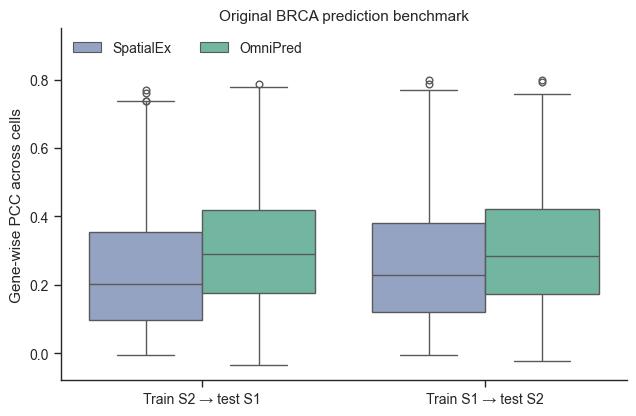

In [5]:
summary = scores.groupby(["direction", "method"]).PCC.agg(
    n_defined="count", mean="mean", median="median",
    q25=lambda x: x.quantile(0.25), q75=lambda x: x.quantile(0.75)).reset_index()
summary.to_csv(OUTPUT / "Fig4_summary.csv", index=False)
display(summary)

sns.set_theme(style="ticks", context="paper", font_scale=1.15)
fig, ax = plt.subplots(figsize=(6.5, 4.3))
sns.boxplot(data=scores, x="direction", y="PCC", hue="method", order=DIRECTIONS,
            hue_order=METHODS, palette={"SpatialEx": "#8da0cb", "OmniPred": "#66c2a5"}, ax=ax)
ax.set_xticks([0, 1], ["Train S2 → test S1", "Train S1 → test S2"])
ax.set_xlabel("")
ax.set_ylabel("Gene-wise PCC across cells")
ax.set_title("Original BRCA prediction benchmark")
ax.legend(title=None, frameon=False, loc="upper left", ncol=2)
ax.set_ylim(-0.08, 0.95)
sns.despine(ax=ax)
fig.tight_layout()
fig.savefig(OUTPUT / "Fig4A_original_benchmark.pdf", bbox_inches="tight")
fig.savefig(OUTPUT / "Fig4A_original_benchmark.png", dpi=180, bbox_inches="tight")
plt.show()

## Source and interpretation

The frozen source excerpt is included as `original_source_cells.json` (zero-based cells 2, 28, 31 and 33 of `Tutorial 1: OmniPred.ipynb`), with its SHA-256. `provenance.json` records the input hashes, cell mapping, and comparison with saved ground-truth matrices. Original server paths are retained only as provenance; execution never accesses them.

The plot recreates the original comparison and scoring population with readable labels, not the final multi-panel manuscript layout. This is scoring of frozen predictions, not end-to-end predictor retraining. It does not establish cross-patient generalization, reliable recovery of every marker, or equivalence with subsequent repaired-triplet experiments.